# 04 Targeting policy and profit (H4)

Question: who should get the Mens email, who should get the Womens email, and who should get no email at all?

Plan (H4 in `analysis_plan.md`):

1. Split customers 50/50 into train and test.
2. On train, estimate the spend uplift of each email in each of 12 cells (past category × recent buyer × newbie).
3. Pick the most profitable action in each cell: profit = margin × spend uplift − cost per email. Base case: margin 30%, cost $0.10 per email. These are assumptions, not data.
4. Evaluate the policy on test with inverse-probability weighting, and compare it with simple rules.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from helpers import load_data

df = load_data()

df["arm"] = "none"
df.loc[df["segment"] == "Mens E-Mail", "arm"] = "mens"
df.loc[df["segment"] == "Womens E-Mail", "arm"] = "womens"
df["emailed"] = (df["arm"] != "none").astype(int)

df["recent_label"] = "older"
df.loc[df["recent"] == 1, "recent_label"] = "recent"
df["newbie_label"] = "old customer"
df.loc[df["newbie"] == 1, "newbie_label"] = "newbie"
df["cell"] = df["past_category"] + " / " + df["recent_label"] + " / " + df["newbie_label"]

print("Number of cells:", df["cell"].nunique())
df["cell"].value_counts().sort_index()

Number of cells: 12


cell
both / older / newbie                  1006
both / older / old customer             963
both / recent / newbie                 2905
both / recent / old customer           1574
mens only / older / newbie             6043
mens only / older / old customer       6689
mens only / recent / newbie            8091
mens only / recent / old customer      7995
womens only / older / newbie           6061
womens only / older / old customer     6653
womens only / recent / newbie          8038
womens only / recent / old customer    7982
Name: count, dtype: int64

## 1. Train / test split

In [2]:
np.random.seed(2026)
order = np.random.permutation(len(df))
half = len(df) // 2
train = df.iloc[order[:half]].copy()
test = df.iloc[order[half:]].copy()

print("Train:", len(train), " Test:", len(test))
print(train["arm"].value_counts())
print(test["arm"].value_counts())

Train: 32000  Test: 32000
arm
womens    10744
mens      10701
none      10555
Name: count, dtype: int64
arm
none      10751
womens    10643
mens      10606
Name: count, dtype: int64


## 2. Cell-level uplift on the training half

For each cell: mean outcome in the Mens arm minus mean in the control arm, and the same for Womens. Done for spend (used for the policy) and also for visit and conversion (for the Excel sheet).

In [3]:
cells = sorted(df["cell"].unique())
cell_rows = []
for cell in cells:
    part = train[train["cell"] == cell]
    c = part[part["arm"] == "none"]
    m = part[part["arm"] == "mens"]
    w = part[part["arm"] == "womens"]
    first = part.iloc[0]
    cell_rows.append({
        "cell": cell,
        "past_category": first["past_category"],
        "recent_buyer": first["recent"],
        "newbie": first["newbie"],
        "customers_all_data": (df["cell"] == cell).sum(),
        "train_n_control": len(c),
        "train_n_mens": len(m),
        "train_n_womens": len(w),
        "control_spend": c["spend"].mean(),
        "mens_spend_uplift": m["spend"].mean() - c["spend"].mean(),
        "womens_spend_uplift": w["spend"].mean() - c["spend"].mean(),
        "mens_visit_uplift": m["visit"].mean() - c["visit"].mean(),
        "womens_visit_uplift": w["visit"].mean() - c["visit"].mean(),
        "mens_conversion_uplift": m["conversion"].mean() - c["conversion"].mean(),
        "womens_conversion_uplift": w["conversion"].mean() - c["conversion"].mean(),
    })

cell_table = pd.DataFrame(cell_rows)
cell_table[["cell", "train_n_control", "train_n_mens", "train_n_womens", "mens_spend_uplift", "womens_spend_uplift", "mens_visit_uplift", "womens_visit_uplift"]].round(4)

,cell,train_n_control,train_n_mens,train_n_womens,mens_spend_uplift,womens_spend_uplift,mens_visit_uplift,womens_visit_uplift
0,both / older / newbie,153,180,177,-3.1158,-2.6499,0.1386,0.0983
1,both / older / old customer,138,166,140,1.4933,0.0000,0.0971,0.0399
2,both / recent / newbie,501,474,471,1.4109,0.2648,0.1203,0.0819
3,both / recent / old customer,253,275,250,2.5172,-1.7857,0.1390,0.0026
4,mens only / older / newbie,969,1024,1049,1.6708,0.2478,0.0488,-0.0080
5,mens only / older / old customer,1107,1096,1121,0.1051,-0.0789,0.0877,0.0273
6,mens only / recent / newbie,1333,1370,1346,0.4966,0.4601,0.0744,0.0267
7,mens only / recent / old customer,1332,1329,1332,1.0811,0.7924,0.0967,-0.0030
8,womens only / older / newbie,954,1014,1007,0.5592,0.8613,0.0630,0.0815
9,womens only / older / old customer,1138,1137,1133,0.6277,0.4378,0.0854,0.0852


## 3. Learn the policy on train

In each cell, profit per customer of each action:

- none: 0
- Mens email: margin × Mens spend uplift − cost
- Womens email: margin × Womens spend uplift − cost

The policy picks the action with the highest profit. Ties go to "none".

In [4]:
def learn_policy(cell_table, margin, cost):
    policy = {}
    for i in range(len(cell_table)):
        row = cell_table.iloc[i]
        profit_mens = margin * row["mens_spend_uplift"] - cost
        profit_womens = margin * row["womens_spend_uplift"] - cost
        action = "none"
        best = 0
        if profit_mens > best:
            action = "mens"
            best = profit_mens
        if profit_womens > best:
            action = "womens"
            best = profit_womens
        policy[row["cell"]] = action
    return policy

margin = 0.30
cost = 0.10
policy = learn_policy(cell_table, margin, cost)

cell_table["profit_mens"] = margin * cell_table["mens_spend_uplift"] - cost
cell_table["profit_womens"] = margin * cell_table["womens_spend_uplift"] - cost
cell_table["policy_action"] = cell_table["cell"].map(policy)
cell_table[["cell", "customers_all_data", "profit_mens", "profit_womens", "policy_action"]].round(4)

,cell,customers_all_data,profit_mens,profit_womens,policy_action
0,both / older / newbie,1006,-1.0348,-0.8950,none
1,both / older / old customer,963,0.3480,-0.1000,mens
2,both / recent / newbie,2905,0.3233,-0.0206,mens
3,both / recent / old customer,1574,0.6552,-0.6357,mens
4,mens only / older / newbie,6043,0.4012,-0.0257,mens
5,mens only / older / old customer,6689,-0.0685,-0.1237,none
6,mens only / recent / newbie,8091,0.0490,0.0380,mens
7,mens only / recent / old customer,7995,0.2243,0.1377,mens
8,womens only / older / newbie,6061,0.0678,0.1584,womens
9,womens only / older / old customer,6653,0.0883,0.0314,mens


## 4. Evaluate on test with inverse-probability weighting (IPW)

We cannot see what a customer would have done under an action they did not get. But every arm had probability 1/3, so the customers whose actual arm happens to equal the policy's action are a random 1/3 of the test set. Weighting them by 1 / (1/3) = 3 gives an unbiased estimate of mean profit per customer if everyone followed the policy:

value = mean over test customers of [ 1(arm = policy action) × profit_i × 3 ], with profit_i = margin × spend_i − cost × 1(emailed).

In [5]:
def policy_value(data, actions, margin, cost):
    profit = margin * data["spend"].values - cost * data["emailed"].values
    follows = (data["arm"].values == actions).astype(int)
    return np.mean(follows * profit * 3)

test_policy_actions = test["cell"].map(policy).values
n_test = len(test)
none_actions = np.array(["none"] * n_test)
mens_actions = np.array(["mens"] * n_test)
womens_actions = np.array(["womens"] * n_test)

value_policy = policy_value(test, test_policy_actions, margin, cost)
value_none = policy_value(test, none_actions, margin, cost)
value_mens = policy_value(test, mens_actions, margin, cost)
value_womens = policy_value(test, womens_actions, margin, cost)
value_random = (value_none + value_mens + value_womens) / 3

print("Profit per customer (test set, margin 30%, cost $0.10)")
print("Targeting policy:", round(value_policy, 4))
print("Email nobody:", round(value_none, 4))
print("Everyone gets Mens:", round(value_mens, 4))
print("Everyone gets Womens:", round(value_womens, 4))
print("Random emails:", round(value_random, 4))

Profit per customer (test set, margin 30%, cost $0.10)
Targeting policy: 0.3412
Email nobody: 0.1888
Everyone gets Mens: 0.3377
Everyone gets Womens: 0.2435
Random emails: 0.2567


## 5. Bootstrap CIs

Resample test customers 1,000 times (the policy stays fixed) and recompute every value and the difference policy − everyone gets Mens.

In [6]:
np.random.seed(2026)
boot = []
for b in range(1000):
    idx = np.random.randint(0, n_test, n_test)
    sample = test.iloc[idx]
    v_policy = policy_value(sample, test_policy_actions[idx], margin, cost)
    v_none = policy_value(sample, none_actions, margin, cost)
    v_mens = policy_value(sample, mens_actions, margin, cost)
    v_womens = policy_value(sample, womens_actions, margin, cost)
    v_random = (v_none + v_mens + v_womens) / 3
    boot.append([v_policy, v_none, v_mens, v_womens, v_random, v_policy - v_mens])

boot = np.array(boot)
names = ["Targeting policy", "Email nobody", "Everyone gets Mens", "Everyone gets Womens", "Random emails", "Policy minus everyone Mens"]
points = [value_policy, value_none, value_mens, value_womens, value_random, value_policy - value_mens]

value_rows = []
for j in range(len(names)):
    low = np.percentile(boot[:, j], 2.5)
    high = np.percentile(boot[:, j], 97.5)
    value_rows.append([names[j], points[j], low, high, points[j] * 64000])

policy_values = pd.DataFrame(value_rows, columns=["policy", "profit_per_customer", "ci_low", "ci_high", "profit_per_64000_customers"])
policy_values = policy_values.round(4)
policy_values.to_csv("results/policy_values.csv", index=False)
policy_values

,policy,profit_per_customer,ci_low,ci_high,profit_per_64000_customers
0,Targeting policy,0.3412,0.2502,0.4446,21835.182
1,Email nobody,0.1888,0.1316,0.2536,12082.626
2,Everyone gets Mens,0.3377,0.2367,0.4387,21613.638
3,Everyone gets Womens,0.2435,0.1720,0.3351,15585.252
4,Random emails,0.2567,0.2070,0.3065,16427.172
5,Policy minus everyone Mens,0.0035,-0.0700,0.0719,221.544


In [7]:
stop_share_test = np.mean(test_policy_actions == "none")
all_actions = df["cell"].map(policy)
stop_share_all = np.mean(all_actions == "none")
mens_share_all = np.mean(all_actions == "mens")
womens_share_all = np.mean(all_actions == "womens")

print("Share of test customers the policy says to stop emailing:", round(stop_share_test, 4))
print("Share of all 64,000 customers: none", round(stop_share_all, 4), " mens", round(mens_share_all, 4), " womens", round(womens_share_all, 4))
print("Emails saved per 64,000 customers vs emailing everyone:", round(stop_share_all * 64000))
print("Profit difference vs everyone gets Mens, per customer:", round(value_policy - value_mens, 4))
print("Profit difference vs everyone gets Mens, per 64,000 customers:", round((value_policy - value_mens) * 64000, 2))

Share of test customers the policy says to stop emailing: 0.2455
Share of all 64,000 customers: none 0.245  mens 0.5347  womens 0.2203
Emails saved per 64,000 customers vs emailing everyone: 15677
Profit difference vs everyone gets Mens, per customer: 0.0035
Profit difference vs everyone gets Mens, per 64,000 customers: 221.54


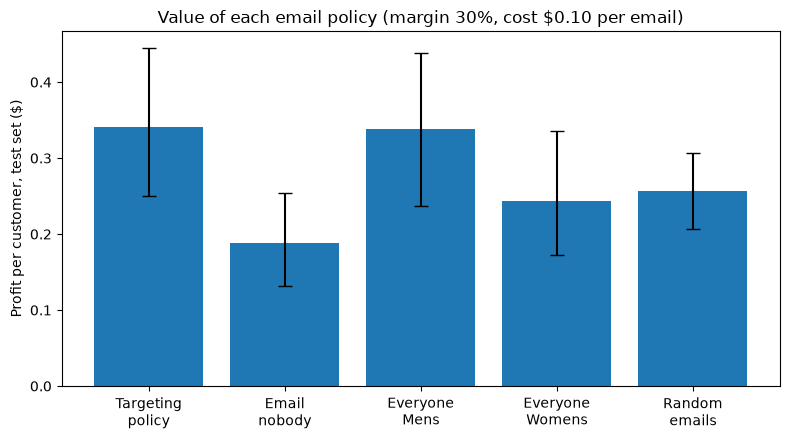

In [8]:
plot_values = policy_values.iloc[:5]
positions = np.arange(len(plot_values))
err = [plot_values["profit_per_customer"] - plot_values["ci_low"], plot_values["ci_high"] - plot_values["profit_per_customer"]]

plt.figure(figsize=(8, 4.5))
plt.bar(positions, plot_values["profit_per_customer"], yerr=err, capsize=5)
plt.xticks(positions, ["Targeting\npolicy", "Email\nnobody", "Everyone\nMens", "Everyone\nWomens", "Random\nemails"])
plt.ylabel("Profit per customer, test set ($)")
plt.title("Value of each email policy (margin 30%, cost $0.10 per email)")
plt.tight_layout()
plt.savefig("figures/policy_values.png", dpi=150)
plt.show()

## 6. Sensitivity: margin × cost per email

For each of the 9 combinations the policy is re-learned on train and evaluated on test.

In [9]:
sens_rows = []
for m_value in [0.20, 0.30, 0.50]:
    for c_value in [0.05, 0.10, 0.50]:
        pol = learn_policy(cell_table, m_value, c_value)
        acts = test["cell"].map(pol).values
        v_policy = policy_value(test, acts, m_value, c_value)
        v_none = policy_value(test, none_actions, m_value, c_value)
        v_mens = policy_value(test, mens_actions, m_value, c_value)
        v_womens = policy_value(test, womens_actions, m_value, c_value)
        stop = np.mean(acts == "none")
        sens_rows.append([m_value, c_value, v_policy, v_none, v_mens, v_womens, v_policy - v_mens, stop])

sensitivity = pd.DataFrame(sens_rows, columns=["margin", "cost_per_email", "policy", "email_nobody", "everyone_mens", "everyone_womens", "policy_minus_mens", "share_not_emailed"])
sensitivity = sensitivity.round(4)
sensitivity.to_csv("results/policy_sensitivity.csv", index=False)
sensitivity

,margin,cost_per_email,policy,email_nobody,everyone_mens,everyone_womens,policy_minus_mens,share_not_emailed
0,0.2,0.05,0.2564,0.1259,0.2417,0.1790,0.0147,0.1207
1,0.2,0.10,0.1889,0.1259,0.1920,0.1291,-0.0031,0.3718
2,0.2,0.50,0.1335,0.1259,-0.2057,-0.2700,0.3393,0.9751
3,0.3,0.05,0.4064,0.1888,0.3874,0.2934,0.0189,0.1207
4,0.3,0.10,0.3412,0.1888,0.3377,0.2435,0.0035,0.2455
5,0.3,0.50,0.2146,0.1888,-0.0600,-0.1556,0.2746,0.8813
6,0.5,0.05,0.6794,0.3147,0.6789,0.5223,0.0005,0.0155
7,0.5,0.10,0.6627,0.3147,0.6291,0.4724,0.0336,0.1207
8,0.5,0.50,0.3443,0.3147,0.2314,0.0733,0.1129,0.5696


In [10]:
table = sensitivity.pivot(index="margin", columns="cost_per_email", values="policy_minus_mens")
print("Policy minus everyone gets Mens, profit per customer ($):")
print(table)
print()
table = sensitivity.pivot(index="margin", columns="cost_per_email", values="share_not_emailed")
print("Share of test customers not emailed under the policy:")
print(table)

Policy minus everyone gets Mens, profit per customer ($):
cost_per_email    0.05    0.10    0.50
margin                                
0.2             0.0147 -0.0031  0.3393
0.3             0.0189  0.0035  0.2746
0.5             0.0005  0.0336  0.1129

Share of test customers not emailed under the policy:
cost_per_email    0.05    0.10    0.50
margin                                
0.2             0.1207  0.3718  0.9751
0.3             0.1207  0.2455  0.8813
0.5             0.0155  0.1207  0.5696


## 7. Input sheet for the Excel profit calculator

One sheet, one row per cell and email type, with the uplift estimates from the training half. The calculator itself is built by hand in Excel (see `excel_guide.md`).

In [11]:
excel_rows = []
for i in range(len(cell_table)):
    row = cell_table.iloc[i]
    for email in ["Mens", "Womens"]:
        key = email.lower()
        excel_rows.append({
            "cell": row["cell"],
            "past_category": row["past_category"],
            "recent_buyer": int(row["recent_buyer"]),
            "newbie": int(row["newbie"]),
            "email": email,
            "customers": int(row["customers_all_data"]),
            "visit_uplift": round(row[key + "_visit_uplift"], 6),
            "conversion_uplift": round(row[key + "_conversion_uplift"], 6),
            "spend_uplift": round(row[key + "_spend_uplift"], 6),
        })

excel_inputs = pd.DataFrame(excel_rows)
excel_inputs.to_excel("excel/email_profit_calculator.xlsx", sheet_name="inputs", index=False)
cell_table.round(6).to_csv("results/cell_uplifts_train.csv", index=False)
excel_inputs

,cell,past_category,recent_buyer,newbie,email,customers,visit_uplift,conversion_uplift,spend_uplift
0,both / older / newbie,both,0,1,Mens,1006,0.138562,-0.008497,-3.115850
1,both / older / newbie,both,0,1,Womens,1006,0.098261,0.002991,-2.649946
2,both / older / old customer,both,0,0,Mens,963,0.097084,0.024096,1.493313
3,both / older / old customer,both,0,0,Womens,963,0.039855,0.000000,0.000000
4,both / recent / newbie,both,1,1,Mens,2905,0.120278,0.019556,1.410890
5,both / recent / newbie,both,1,1,Womens,2905,0.081887,0.011251,0.264819
6,both / recent / old customer,both,1,0,Mens,1574,0.138972,0.017233,2.517230
7,both / recent / old customer,both,1,0,Womens,1574,0.002609,-0.003858,-1.785683
8,mens only / older / newbie,mens only,0,1,Mens,6043,0.048820,0.014648,1.670791
9,mens only / older / newbie,mens only,0,1,Womens,6043,-0.007984,0.001907,0.247788


## Summary

Base case (margin 30%, cost $0.10 per email), profit per customer on the **test** half:

| Policy | Profit per customer | 95% bootstrap CI |
|---|---|---|
| Targeting policy | $0.341 | $0.250 to $0.445 |
| Everyone gets Mens | $0.338 | $0.237 to $0.439 |
| Random emails | $0.257 | $0.207 to $0.307 |
| Everyone gets Womens | $0.244 | $0.172 to $0.335 |
| Email nobody | $0.189 | $0.132 to $0.254 |

- **Emailing pays.** Every emailing policy beats emailing nobody. The Mens email for everyone adds about $0.15 per customer.
- **Targeting gives the same profit with a quarter fewer emails.** The policy tells the company to stop emailing **24.5%** of customers (about 15,700 of 64,000) and send the Womens email to 22%. Its profit is $0.0035 per customer higher than "everyone gets Mens", but the CI is −$0.070 to $0.072, so on profit alone there is **no measurable gain**. The honest claim is: same profit, 25% fewer messages. Fewer messages also means fewer chances to annoy customers into unsubscribing, which this 2-week profit number does not count.
- **Cells to stop emailing (base case):** both-category older newbies, mens-only older old customers, and womens-only recent old customers.
- **Sensitivity:** when emails are cheap ($0.05), the policy emails 88% or more of customers and is roughly equal to "everyone gets Mens". When emails are expensive ($0.50), blanket emailing loses money (−$0.06 per customer at 30% margin) and targeting wins clearly (+$0.27 per customer vs everyone Mens, emailing only about 12% of customers). So targeting matters most when each message is costly.
- **Caveat:** some cells have only about 150 customers per arm in the training half, so their spend uplifts are noisy (for example −$3.12 for both-category older newbies). That noise is the main reason the learned policy does not beat the simple rule by more. A larger experiment or a smoother model (for example pooling across cells) would help, but that would be **Exploratory**.